# Лабораторна робота №3. Нейронні мережі для табличних даних, зображень і текстів

Усі моделі побудовано на PyTorch і навчено на CPU. Для навчання і перевірки використано одну функцію `train` і одну функцію `predict`, тому цикл навчання скрізь однаковий. Для оцінки використано `classification_report` з sklearn, як у лабораторних роботах 1 і 2.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from collections import Counter
from torch.utils.data import TensorDataset, DataLoader
from torchvision import models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

torch.manual_seed(42)

## Спільні функції

In [2]:
def train(model, train_loader, val_loader, epochs, lr):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    train_losses, val_losses = [], []
    start = time.time()
    for epoch in range(epochs):
        model.train()  # режим навчання
        total = 0
        for x, y in train_loader:
            optimizer.zero_grad()  # обнуляємо старі градієнти
            loss = criterion(model(x), y)  # прямий прохід і втрата
            loss.backward()  # градієнти
            optimizer.step()  # оновлення ваг
            total += loss.item() * len(x)
        train_losses.append(total / len(train_loader.dataset))
        model.eval()  # режим перевірки
        total = 0
        with torch.no_grad():  # градієнти не потрібні
            for x, y in val_loader:
                total += criterion(model(x), y).item() * len(x)
        val_losses.append(total / len(val_loader.dataset))
        print(f'[{epoch + 1:02d}] train_loss={train_losses[-1]:.4f} val_loss={val_losses[-1]:.4f}')
    return train_losses, val_losses, time.time() - start

In [3]:
def predict(model, X):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(x).argmax(1) for x in X.split(256)]).numpy()

In [4]:
def plot_curves(curves):  # curves: {назва: (train_losses, val_losses)}
    fig, axes = plt.subplots(1, len(curves), figsize=(5 * len(curves), 4), sharey=True, squeeze=False)
    for ax, (name, (train_losses, val_losses)) in zip(axes[0], curves.items()):
        ax.plot(range(1, len(train_losses) + 1), train_losses, label='train')
        ax.plot(range(1, len(val_losses) + 1), val_losses, label='validation')
        ax.set_title(name)
        ax.set_xlabel('Епоха')
        ax.set_ylabel('Loss')
        ax.legend()
        ax.grid()
    plt.show()

`train` для кожної епохи проходить по train_loader (оновлює ваги), потім рахує loss на validation без оновлення ваг і повертає списки loss та час навчання. `predict` повертає передбачені класи для тензора ознак.

## 1. Повнозв'язана нейронна мережа (MLP)

Датасет Phishing Dataset for Machine Learning з лабораторної роботи №1. Підготовка та сама, що в лабі 1, тому тестова вибірка ідентична.

In [5]:
df = pd.read_csv('../../data/phishing_ml/Phishing_Legitimate_full.csv')
df = df.drop('id', axis=1)  # id це номер рядка
df = df.drop_duplicates()  # до розбиття
X = df.drop('CLASS_LABEL', axis=1)
y = df['CLASS_LABEL']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # fit лише на train
X_test_scaled = scaler.transform(X_test)
X_train.shape, X_test.shape

((7664, 48), (1917, 48))

Розбиття збігається з лабою 1 (7664 train і 1917 test). З train виділяємо 20% під validation, щоб будувати learning curves. Тест у навчанні не бере участі.

In [6]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train_scaled, y_train, test_size=0.2, stratify=y_train, random_state=42)
X_tr, X_val, X_te = [torch.tensor(a, dtype=torch.float32) for a in (X_tr, X_val, X_test_scaled)]
y_tr, y_val, y_te = [torch.tensor(a.values) for a in (y_tr, y_val, y_test)]
train_loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=64, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=64)
X_tr.shape, X_val.shape

(torch.Size([6131, 48]), torch.Size([1533, 48]))

In [7]:
torch.manual_seed(42)
mlp = nn.Sequential(
    nn.Linear(48, 64), nn.ReLU(),
    nn.Linear(64, 32), nn.ReLU(),
    nn.Linear(32, 2))  # 2 виходи (logits) для CrossEntropyLoss
mlp_train, mlp_val, mlp_time = train(mlp, train_loader, val_loader, epochs=20, lr=1e-3)

[01] train_loss=0.4022 val_loss=0.1826
[02] train_loss=0.1500 val_loss=0.1531
[03] train_loss=0.1255 val_loss=0.1382


[04] train_loss=0.1095 val_loss=0.1288
[05] train_loss=0.0977 val_loss=0.1249
[06] train_loss=0.0865 val_loss=0.1197


[07] train_loss=0.0770 val_loss=0.1120
[08] train_loss=0.0700 val_loss=0.1117
[09] train_loss=0.0620 val_loss=0.1062


[10] train_loss=0.0549 val_loss=0.1039
[11] train_loss=0.0515 val_loss=0.1053
[12] train_loss=0.0466 val_loss=0.1094


[13] train_loss=0.0439 val_loss=0.1089
[14] train_loss=0.0409 val_loss=0.1044
[15] train_loss=0.0361 val_loss=0.1063


[16] train_loss=0.0328 val_loss=0.1109
[17] train_loss=0.0310 val_loss=0.1137
[18] train_loss=0.0273 val_loss=0.1239


[19] train_loss=0.0282 val_loss=0.1218
[20] train_loss=0.0288 val_loss=0.1247


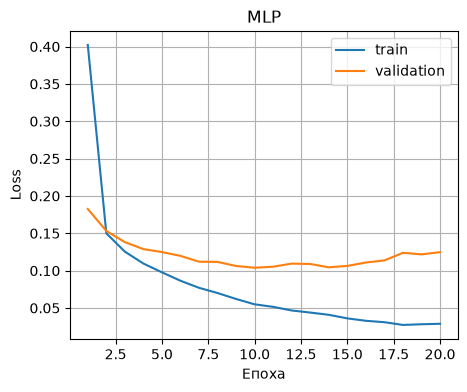

In [8]:
plot_curves({'MLP': (mlp_train, mlp_val)})

In [9]:
print('мінімум val_loss на епосі', int(np.argmin(mlp_val)) + 1, 'значення', round(min(mlp_val), 4))
print('останній train_loss', round(mlp_train[-1], 4), 'val_loss', round(mlp_val[-1], 4))

мінімум val_loss на епосі 10 значення 0.1039
останній train_loss 0.0288 val_loss 0.1247


Train loss безперервно падає (до 0,029), а validation loss мінімальний на епосі 10 (0,1039) і далі росте (до 0,1247 на епосі 20). Отже, після приблизно 10 епох спостерігається перенавчання, бо модель починає запам'ятовувати train. Тест оцінюємо після всіх 20 епох без ранньої зупинки.

In [10]:
pred_mlp = predict(mlp, X_te)
print(classification_report(y_test, pred_mlp))
confusion_matrix(y_test, pred_mlp)

              precision    recall  f1-score   support

           0       0.98      0.96      0.97      1000
           1       0.95      0.98      0.97       917

    accuracy                           0.97      1917
   macro avg       0.97      0.97      0.97      1917
weighted avg       0.97      0.97      0.97      1917



array([[956,  44],
       [ 19, 898]])

### Порівняння з класичними алгоритмами лабораторної роботи №1

Результати класичних моделей взято з підсумкової таблиці лабораторної роботи №1 (accuracy на тесті з 1917 об'єктів, розбиття те саме, тому порівняння коректне). Тут вони вписані як константи, щоб не перенавчати їх повторно.

In [11]:
lab1 = {'kNN': 0.9452, 'Decision Tree': 0.9703, 'SVM': 0.9744, 'Random Forest': 0.9880, 'AdaBoost': 0.9635}
lab1['MLP (ця робота)'] = accuracy_score(y_test, pred_mlp)
table = pd.DataFrame({'accuracy': lab1})
table['помилок з 1917'] = ((1 - table['accuracy']) * 1917).round().astype(int)
table.round(4)

,accuracy,помилок з 1917
kNN,0.9452,105
Decision Tree,0.9703,57
SVM,0.9744,49
Random Forest,0.9880,23
AdaBoost,0.9635,70
MLP (ця робота),0.9671,63


MLP дала accuracy 0,9671 (63 помилки з 1917), обидва класи розпізнано збалансовано (recall 0,96 і 0,98). Вона краще за kNN (0,9452, на 42 об'єкти менше помилок), практично така сама, як AdaBoost (0,9635) і Decision Tree (0,9703), трохи гірша за SVM (0,9744, на 14 об'єктів) і помітно гірша за Random Forest (0,9880, лише 23 помилки). Для табличних даних із різнорідними ознаками ансамбль дерев лишається найкращим, нейронна мережа виграшу не дала. Також MLP навчалась на 80% train (решта 20% пішла у validation), а класичні моделі на всьому train.

## 2. Згорткові нейронні мережі

### Датасет

Датасет Fashion-MNIST (Zalando), https://github.com/zalandoresearch/fashion-mnist . Це чорно-білі зображення предметів одягу розміром 28 на 28 пікселів, 10 класів. У файлі кожен рядок містить мітку label і 784 значення пікселів від 0 до 255. MNIST і CIFAR-10 за умовою не використовуються.

In [12]:
train_df = pd.read_csv('../../data/fashion_mnist/fashion-mnist_train.csv')
test_df = pd.read_csv('../../data/fashion_mnist/fashion-mnist_test.csv')
names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
print(train_df.shape, test_df.shape)
train_df['label'].value_counts().sort_index()

(60000, 785) (10000, 785)


label
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64

У train 60000 зображень, у test 10000. Класів 10, у train їх порівну (по 6000). Класи 0 T-shirt/top, 1 Trouser, 2 Pullover, 3 Dress, 4 Coat, 5 Sandal, 6 Shirt, 7 Sneaker, 8 Bag, 9 Ankle boot.

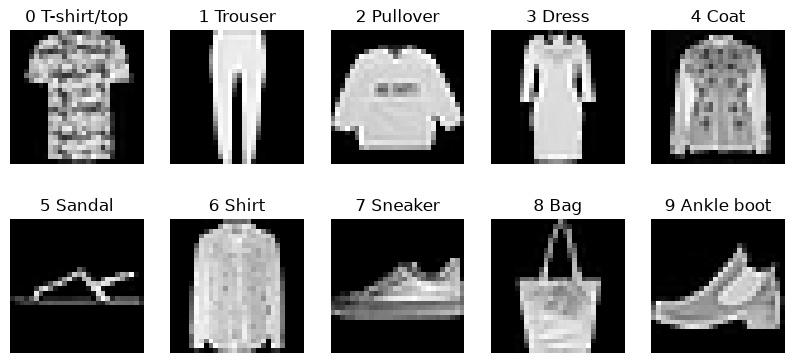

In [13]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for c, ax in enumerate(axes.flatten()):
    row = train_df[train_df['label'] == c].iloc[0]  # перший приклад класу
    ax.imshow(row.drop('label').values.reshape(28, 28), cmap='gray')
    ax.set_title(f'{c} {names[c]}')
    ax.axis('off')
plt.show()

### Підготовка даних

Щоб навчання на CPU було швидким, беремо випадкову підвибірку 12000 зображень train (10000 для навчання і 2000 для validation) і 2000 зображень test. Для порівняння впливу обсягу даних також використаємо малу підвибірку з перших 500 навчальних зображень.

In [14]:
sub = train_df.sample(12000, random_state=42)  # перемішана підвибірка
test_sub = test_df.sample(2000, random_state=42)
X_all = torch.tensor(sub.drop('label', axis=1).values / 255, dtype=torch.float32).reshape(-1, 1, 28, 28)
y_all = torch.tensor(sub['label'].values)
X_te = torch.tensor(test_sub.drop('label', axis=1).values / 255, dtype=torch.float32).reshape(-1, 1, 28, 28)
y_te = torch.tensor(test_sub['label'].values)
X_tr, X_val = X_all[:10000], X_all[10000:]
y_tr, y_val = y_all[:10000], y_all[10000:]
X_tr.shape, X_val.shape, X_te.shape  # [зображень, канал, висота, ширина]

(torch.Size([10000, 1, 28, 28]),
 torch.Size([2000, 1, 28, 28]),
 torch.Size([2000, 1, 28, 28]))

In [15]:
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=64)
train_loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=64, shuffle=True)
train_loader_small = DataLoader(TensorDataset(X_tr[:500], y_tr[:500]), batch_size=64, shuffle=True)

### 2а. Проста CNN з нуля

In [16]:
torch.manual_seed(42)
cnn = nn.Sequential(
    nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # [16, 14, 14]
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # [32, 7, 7]
    nn.Flatten(),                                                  # [1568]
    nn.Linear(32 * 7 * 7, 10))                                     # 10 класів
cnn_train, cnn_val, cnn_time = train(cnn, train_loader, val_loader, epochs=15, lr=1e-3)

[01] train_loss=0.9237 val_loss=0.5474


[02] train_loss=0.5335 val_loss=0.4704


[03] train_loss=0.4586 val_loss=0.4219


[04] train_loss=0.4106 val_loss=0.4040


[05] train_loss=0.3849 val_loss=0.4184


[06] train_loss=0.3634 val_loss=0.3824


... (5 outputs left out)

[12] train_loss=0.2895 val_loss=0.3281


[13] train_loss=0.2750 val_loss=0.3224


[14] train_loss=0.2665 val_loss=0.3521


[15] train_loss=0.2597 val_loss=0.3268


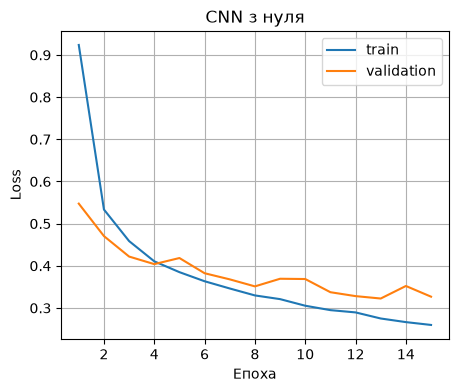

In [17]:
plot_curves({'CNN з нуля': (cnn_train, cnn_val)})

Train loss плавно падає до 0,26, validation loss до 0,32 (мінімум 0,3224 на епосі 13) з невеликими коливаннями. Розрив між кривими малий, тому сильного перенавчання за 15 епох немає, і модель можна було б навчати довше.

In [18]:
pred_cnn = predict(cnn, X_te)
print(classification_report(y_te, pred_cnn, target_names=names))

              precision    recall  f1-score   support

 T-shirt/top       0.82      0.78      0.80       192
     Trouser       0.96      0.98      0.97       192
    Pullover       0.88      0.76      0.81       212
       Dress       0.88      0.91      0.89       205
        Coat       0.84      0.80      0.82       204
      Sandal       0.96      0.98      0.97       193
       Shirt       0.61      0.72      0.66       200
     Sneaker       0.91      0.96      0.93       206
         Bag       0.98      0.96      0.97       196
  Ankle boot       0.97      0.91      0.94       200

    accuracy                           0.88      2000
   macro avg       0.88      0.88      0.88      2000
weighted avg       0.88      0.88      0.88      2000



### 2б. Pretrained ResNet18

Беремо ResNet18, навчену на ImageNet, і замінюємо останній шар `fc` на `Linear(512, 10)`. Донавчаємо всі шари з малим lr 0,0001, щоб ознаки, вивчені на кольорових фото ImageNet, поступово пристосувалися до маленьких чорно-білих зображень одягу. Одноканальне зображення повторюємо на 3 канали й нормалізуємо як ImageNet, а розмір збільшуємо до 64 на 64 шаром `nn.Upsample` усередині моделі.

In [19]:
mean = torch.tensor([0.485, 0.456, 0.406]).reshape(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).reshape(1, 3, 1, 1)
R_tr, R_val, R_te = [(a.repeat(1, 3, 1, 1) - mean) / std for a in (X_tr, X_val, X_te)]  # 1 канал в 3 і нормалізація
res_loader = DataLoader(TensorDataset(R_tr, y_tr), batch_size=64, shuffle=True)
res_loader_small = DataLoader(TensorDataset(R_tr[:500], y_tr[:500]), batch_size=64, shuffle=True)
res_val_loader = DataLoader(TensorDataset(R_val, y_val), batch_size=64)
R_tr.shape

torch.Size([10000, 3, 28, 28])

In [20]:
torch.manual_seed(42)
resnet = models.resnet18(weights='DEFAULT')  # ваги ImageNet
resnet.fc = nn.Linear(512, 10)  # новий класифікатор
res_model = nn.Sequential(nn.Upsample(size=64), resnet)  # 28x28 в 64x64
res_train, res_val, res_time = train(res_model, res_loader, res_val_loader, epochs=8, lr=1e-4)

[01] train_loss=0.5402 val_loss=0.3104


[02] train_loss=0.2172 val_loss=0.2760


[03] train_loss=0.1307 val_loss=0.2915


[04] train_loss=0.0793 val_loss=0.2989


[05] train_loss=0.0416 val_loss=0.3535


[06] train_loss=0.0376 val_loss=0.3737


[07] train_loss=0.0403 val_loss=0.3870


[08] train_loss=0.0348 val_loss=0.3678


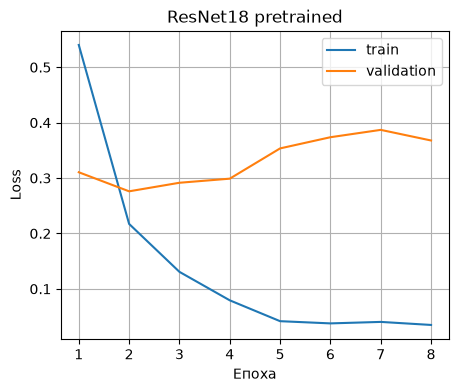

In [21]:
plot_curves({'ResNet18 pretrained': (res_train, res_val)})

In [22]:
pred_res = predict(res_model, R_te)
print(classification_report(y_te, pred_res, target_names=names))

              precision    recall  f1-score   support

 T-shirt/top       0.87      0.79      0.83       192
     Trouser       0.98      0.97      0.98       192
    Pullover       0.86      0.87      0.87       212
       Dress       0.85      0.97      0.90       205
        Coat       0.89      0.76      0.82       204
      Sandal       0.99      0.98      0.99       193
       Shirt       0.68      0.76      0.72       200
     Sneaker       0.95      0.97      0.96       206
         Bag       0.99      0.97      0.98       196
  Ankle boot       0.97      0.95      0.96       200

    accuracy                           0.90      2000
   macro avg       0.90      0.90      0.90      2000
weighted avg       0.90      0.90      0.90      2000



Validation loss мінімальний уже на епосі 2 (0,2760), далі росте до 0,37, тоді як train loss падає до 0,035. Тобто pretrained ResNet18 дуже швидко вчиться, але потім перенавчається (11 млн параметрів на 10000 зображень). Тест оцінено після всіх 8 епох, без ранньої зупинки. Найгірше розпізнається клас Shirt (f1 0,72), бо схожий на T-shirt, Pullover і Coat.

### 2в. Вплив обсягу тренувальних даних

Обидві моделі навчаємо ще раз на 500 зображеннях з тим самим кодом, тими самими епохами та lr. Validation і test ті самі.

In [23]:
torch.manual_seed(42)
cnn_s = nn.Sequential(
    nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(32 * 7 * 7, 10))
cnn_s_train, cnn_s_val, cnn_s_time = train(cnn_s, train_loader_small, val_loader, epochs=15, lr=1e-3)
pred_cnn_s = predict(cnn_s, X_te)

[01] train_loss=2.2394 val_loss=2.1218
[02] train_loss=1.9599 val_loss=1.7298


[03] train_loss=1.4928 val_loss=1.2435


[04] train_loss=1.1017 val_loss=0.9842


[05] train_loss=0.8938 val_loss=0.8430
[06] train_loss=0.7814 val_loss=0.8065


[07] train_loss=0.7321 val_loss=0.7893
[08] train_loss=0.6950 val_loss=0.7378


[09] train_loss=0.6499 val_loss=0.7146
[10] train_loss=0.6335 val_loss=0.7151


[11] train_loss=0.6039 val_loss=0.6916
[12] train_loss=0.5773 val_loss=0.6804


[13] train_loss=0.5693 val_loss=0.6707
[14] train_loss=0.5418 val_loss=0.6504


[15] train_loss=0.5069 val_loss=0.6378


In [24]:
torch.manual_seed(42)
resnet_s = models.resnet18(weights='DEFAULT')
resnet_s.fc = nn.Linear(512, 10)
res_s_model = nn.Sequential(nn.Upsample(size=64), resnet_s)
res_s_train, res_s_val, res_s_time = train(res_s_model, res_loader_small, res_val_loader, epochs=8, lr=1e-4)
pred_res_s = predict(res_s_model, R_te)

[01] train_loss=1.8456 val_loss=1.5810


[02] train_loss=0.5831 val_loss=0.9769


[03] train_loss=0.2482 val_loss=0.8160


[04] train_loss=0.1025 val_loss=0.7335


[05] train_loss=0.0486 val_loss=0.6752


[06] train_loss=0.0304 val_loss=0.6194


[07] train_loss=0.0179 val_loss=0.5740


[08] train_loss=0.0122 val_loss=0.5555


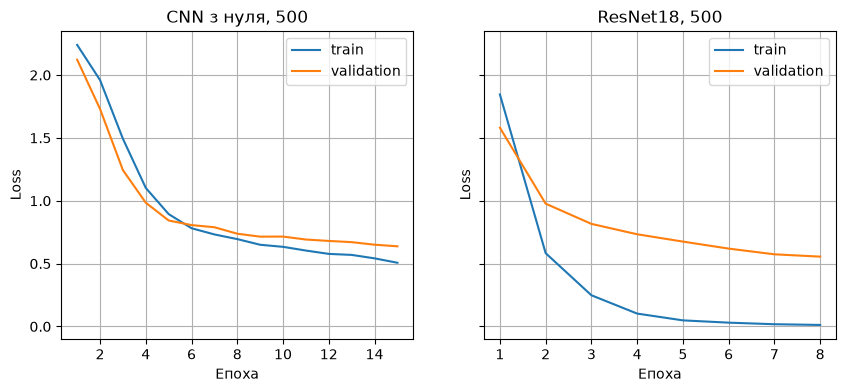

In [25]:
plot_curves({'CNN з нуля, 500': (cnn_s_train, cnn_s_val), 'ResNet18, 500': (res_s_train, res_s_val)})

### Порівняння CNN з нуля і ResNet18

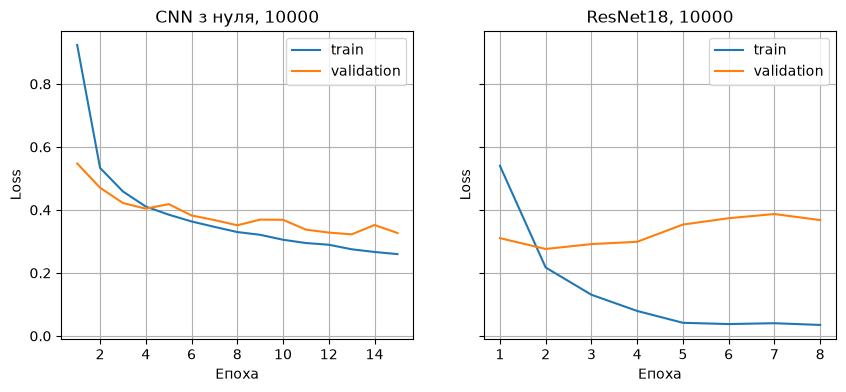

In [26]:
plot_curves({'CNN з нуля, 10000': (cnn_train, cnn_val), 'ResNet18, 10000': (res_train, res_val)})

In [27]:
comparison = pd.DataFrame({
    'модель': ['CNN з нуля', 'ResNet18 pretrained'],
    'epochs': [15, 8],
    'accuracy (10000)': [accuracy_score(y_te, pred_cnn), accuracy_score(y_te, pred_res)],
    'accuracy (500)': [accuracy_score(y_te, pred_cnn_s), accuracy_score(y_te, pred_res_s)],
    'епоха мінімуму val_loss (10000)': [int(np.argmin(cnn_val)) + 1, int(np.argmin(res_val)) + 1],
    'мін. val_loss (10000)': [min(cnn_val), min(res_val)],
    'епоха мінімуму val_loss (500)': [int(np.argmin(cnn_s_val)) + 1, int(np.argmin(res_s_val)) + 1],
    'час, с (10000)': [cnn_time, res_time],
    'час, с (500)': [cnn_s_time, res_s_time]})
comparison.round(4).T

,0,1
модель,CNN з нуля,ResNet18 pretrained
epochs,15,8
accuracy (10000),0.876,0.9
accuracy (500),0.776,0.811
епоха мінімуму val_loss (10000),13,2
мін. val_loss (10000),0.3224,0.276
епоха мінімуму val_loss (500),15,8
"час, с (10000)",14.4647,454.4224
"час, с (500)",3.0087,45.5775


Якість. ResNet18 краща (accuracy 0,900 проти 0,876), різниця 0,024 це 48 зображень з 2000. Швидкість збіжності. У ResNet мінімум val_loss на епосі 2 (0,276), у CNN на епосі 13 (0,322), але на CPU ResNet навчалась 454 с проти 14 с, тобто у 31 раз довше. Learning curves. CNN з нуля має плавні криві без перенавчання, а в ResNet після епохи 2 validation loss росте. Обсяг даних. На 500 зображеннях accuracy впала в обох моделей (CNN 0,776, ResNet 0,811), а перевага ResNet лишилась (3,5 п.п., 70 зображень) і не стала помітно більшою, ніж на 10000 (2,4 п.п.). При цьому на 500 зображеннях validation loss ще падав на останній епосі, тож за 15 і 8 епох моделі недонавчились, і різниця між ними при довшому навчанні могла б змінитись.

Pretrained ResNet18 дала вищу якість (0,900 проти 0,876) і сходиться за 2 епохи, але навчається у 31 раз довше на CPU і швидко перенавчається, тому їй потрібна рання зупинка. Проста CNN значно швидша, майже не перенавчається, а її accuracy нижча на 2,4 п.п. На малій вибірці в 500 зображень обидві моделі втрачають близько 9-10 п.п. accuracy, а перевага pretrained зберігається (3,5 п.п.). Різниця між CNN і ResNet тут помірна, бо Fashion-MNIST проста задача.

## 3. Класифікація текстів (SMS Spam)

Той самий датасет, що в лабораторній роботі №2 (SMS Spam Collection, UCI). Дублікати видаляємо до розбиття. На відміну від лаби 2 стоп-слова не видаляємо, лише переводимо в малі літери й прибираємо пунктуацію та цифри, бо для послідовності слова зі стоп-слів теж частина речення, а GloVe містить і їх.

In [28]:
sms = pd.read_csv('../../data/sms_spam/spam.csv', encoding='latin-1')[['v1', 'v2']]
sms.columns = ['label', 'text']
sms = sms.drop_duplicates()  # до розбиття
sms['clean'] = sms['text'].str.lower().str.replace(r'[^a-z\s]', ' ', regex=True)
sms['y'] = (sms['label'] == 'spam').astype(int)  # spam = 1
sms['label'].value_counts()

label
ham     4516
spam     653
Name: count, dtype: int64

In [29]:
t_train, t_test, yt_train, yt_test = train_test_split(sms['clean'], sms['y'], test_size=0.2, stratify=sms['y'], random_state=42)
t_tr, t_val, yt_tr, yt_val = train_test_split(t_train, yt_train, test_size=0.2, stratify=yt_train, random_state=42)
len(t_tr), len(t_val), len(t_test)

(3308, 827, 1034)

Розбиття 80 на 20 те саме, що в лабі 2 (тест 1034 повідомлення, з них 131 spam). З train ще 20% іде під validation.

### 3.1 Токенізація, словник, індекси, padding

In [30]:
words = [w for text in t_tr for w in text.split()]  # токенізація через split
counter = Counter(words)  # словник лише по train
word2idx = {w: i + 2 for i, w in enumerate(counter)}  # 0 для padding, 1 для невідомих слів
lengths = [len(text.split()) for text in t_tr]
max_len = int(np.percentile(lengths, 95))
len(word2idx) + 2, max_len, max(lengths)

(5957, 33, 117)

У словнику 5955 слів і ще 2 службові індекси (всього 5957). 95-й перцентиль довжини повідомлення дорівнює 33 словам (максимум 117), тому max_len = 33, довші повідомлення обрізаються.

In [31]:
def encode(texts):
    ids = [[word2idx.get(w, 1) for w in text.split()] for text in texts]  # слова в індекси
    return torch.tensor([([0] * max_len + row)[-max_len:] for row in ids])  # padding зліва і обрізання до max_len

T_tr, T_val, T_te = encode(t_tr), encode(t_val), encode(t_test)
yt_tr, yt_val, yt_te = [torch.tensor(a.values) for a in (yt_tr, yt_val, yt_test)]
text_loader = DataLoader(TensorDataset(T_tr, yt_tr), batch_size=32, shuffle=True)
text_val_loader = DataLoader(TensorDataset(T_val, yt_val), batch_size=32)
print(T_tr.shape)
print(t_tr.iloc[0])
print(T_tr[0])

torch.Size([3308, 33])
urgent   your mobile no  was awarded a         bonus caller prize on           this is our  nd attempt to contact you  call               box  qu
tensor([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  2,  3,  4,  5,  6,  7,  8,
         9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23])


Padding додаємо зліва, щоб останній стан LSTM відповідав останньому справжньому слову, а не нулям. Довші повідомлення обрізаємо до max_len слів (лишаємо кінець).

### 3а. Embedding з випадковими вагами + LSTM

In [32]:
class LSTMClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(word2idx) + 2, 100, padding_idx=0)  # індекс слова в вектор 100
        self.lstm = nn.LSTM(100, 64, batch_first=True)
        self.fc = nn.Linear(64, 2)

    def forward(self, x):  # x: [batch, max_len]
        out, (h, c) = self.lstm(self.emb(x))  # h: останній прихований стан [1, batch, 64]
        return self.fc(h[-1])

In [33]:
torch.manual_seed(42)
lstm_rand = LSTMClassifier()
rand_train, rand_val, rand_time = train(lstm_rand, text_loader, text_val_loader, epochs=15, lr=1e-3)

[01] train_loss=0.3153 val_loss=0.1454


[02] train_loss=0.1127 val_loss=0.0973


[03] train_loss=0.0500 val_loss=0.0946


[04] train_loss=0.0249 val_loss=0.1088


[05] train_loss=0.0167 val_loss=0.0963


[06] train_loss=0.0088 val_loss=0.1154


... (5 outputs left out)

[12] train_loss=0.0006 val_loss=0.1727


[13] train_loss=0.0004 val_loss=0.1805


[14] train_loss=0.0004 val_loss=0.1930


[15] train_loss=0.0002 val_loss=0.2046


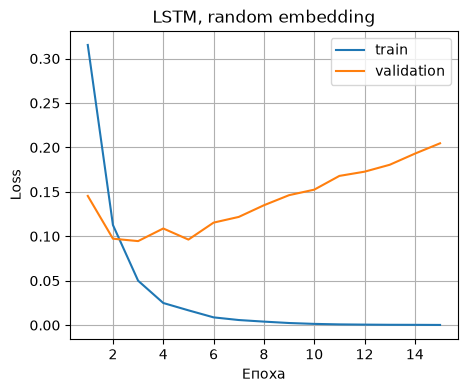

In [34]:
plot_curves({'LSTM, random embedding': (rand_train, rand_val)})

In [35]:
pred_rand = predict(lstm_rand, T_te)
print(classification_report(yt_te, pred_rand, target_names=['ham', 'spam']))
confusion_matrix(yt_te, pred_rand)

              precision    recall  f1-score   support

         ham       0.99      0.97      0.98       903
        spam       0.80      0.93      0.86       131

    accuracy                           0.96      1034
   macro avg       0.90      0.95      0.92      1034
weighted avg       0.97      0.96      0.96      1034



array([[873,  30],
       [  9, 122]])

### 3б. Embedding з GloVe + LSTM

GloVe 100d (glove.6B.100d.txt, 400000 слів). Читаємо файл рядок за рядком, і для слів зі словника записуємо вектор у матрицю ваг Embedding. Слова, яких немає в GloVe, лишаються з тими самими випадковими вагами, що й у моделі 3а. Ваги Embedding далі донавчаються разом з усією моделлю.

In [36]:
torch.manual_seed(42)
lstm_glove = LSTMClassifier()  # та сама ініціалізація, що в 3а
weights = lstm_glove.emb.weight.data
found = 0
for line in open('../../data/glove/glove.6B.100d.txt', encoding='utf-8'):
    parts = line.split()
    if parts[0] in word2idx:
        weights[word2idx[parts[0]]] = torch.tensor([float(v) for v in parts[1:]])
        found += 1
print('знайдено в GloVe', found, 'зі', len(word2idx), 'слів, частка', round(found / len(word2idx), 4))

знайдено в GloVe 5091 зі 5955 слів, частка 0.8549


In [37]:
glove_train, glove_val, glove_time = train(lstm_glove, text_loader, text_val_loader, epochs=15, lr=1e-3)

[01] train_loss=0.2749 val_loss=0.2666


[02] train_loss=0.0862 val_loss=0.0992


[03] train_loss=0.0523 val_loss=0.0740


[04] train_loss=0.0316 val_loss=0.0604


[05] train_loss=0.0205 val_loss=0.0697


[06] train_loss=0.0134 val_loss=0.0688


... (5 outputs left out)

[12] train_loss=0.0004 val_loss=0.0805


[13] train_loss=0.0003 val_loss=0.0828


[14] train_loss=0.0002 val_loss=0.0896


[15] train_loss=0.0002 val_loss=0.0976


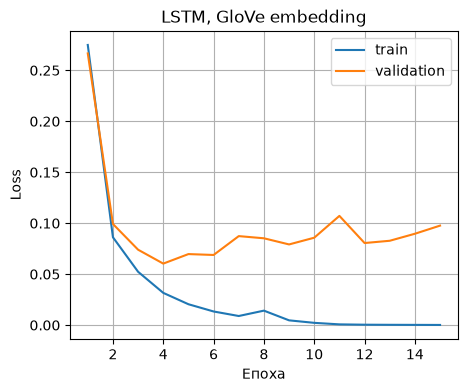

In [38]:
plot_curves({'LSTM, GloVe embedding': (glove_train, glove_val)})

In [39]:
pred_glove = predict(lstm_glove, T_te)
print(classification_report(yt_te, pred_glove, target_names=['ham', 'spam']))
confusion_matrix(yt_te, pred_glove)

              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       903
        spam       0.99      0.88      0.93       131

    accuracy                           0.98      1034
   macro avg       0.99      0.94      0.96      1034
weighted avg       0.98      0.98      0.98      1034



array([[902,   1],
       [ 16, 115]])

### Порівняння двох підходів

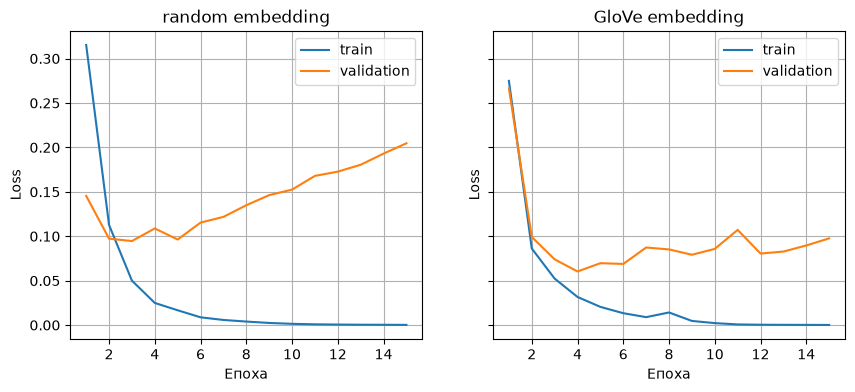

In [40]:
plot_curves({'random embedding': (rand_train, rand_val), 'GloVe embedding': (glove_train, glove_val)})

In [41]:
text_table = pd.DataFrame({
    'модель': ['Embedding random', 'Embedding GloVe'],
    'accuracy': [accuracy_score(yt_te, pred_rand), accuracy_score(yt_te, pred_glove)],
    'f1 spam': [f1_score(yt_te, pred_rand), f1_score(yt_te, pred_glove)],
    'епоха мінімуму val_loss': [int(np.argmin(rand_val)) + 1, int(np.argmin(glove_val)) + 1],
    'мін. val_loss': [min(rand_val), min(glove_val)],
    'час, с': [rand_time, glove_time]})
text_table.round(4)

,модель,accuracy,f1 spam,епоха мінімуму val_loss,мін. val_loss,"час, с"
0,Embedding random,0.9623,0.8622,3,0.0946,8.4448
1,Embedding GloVe,0.9836,0.9312,4,0.0604,8.2327


У GloVe знайдено 5091 з 5955 слів словника (85,5%), решта 864 слова (помилки, сленг, скорочення) лишилися з випадковими векторами. Якість. З GloVe accuracy 0,9836 і f1 для spam 0,9312, з випадковим embedding 0,9623 і 0,8622, тобто 17 і 39 помилок з 1034. Типи помилок різні, випадковий embedding частіше хибно позначає ham як spam (30 проти 1), GloVe частіше пропускає spam (16 проти 9). Швидкість і стабільність. Час навчання однаковий (близько 8 с). З GloVe мінімум validation loss нижчий (0,060 проти 0,095), а після мінімуму validation loss росте повільніше (до 0,098 проти 0,205). В обох моделей train loss прямує до нуля, а validation loss після 3-5 епох починає рости, тобто обидві перенавчаються. Тест оцінено після 15 епох без ранньої зупинки.

З GloVe модель дала вищу якість (f1 для spam 0,93 проти 0,86) і нижчий validation loss за однакового часу навчання. Готові вектори вже містять знання про значення слів, тому моделі менше доводиться вчити з невеликої вибірки (3308 повідомлень). Водночас спамових повідомлень у тесті лише 131, а результат нейромережі залежить від випадкової початкової ініціалізації ваг, тому різницю між підходами варто сприймати обережно.

На табличних даних MLP (0,9671) обігнала kNN, практично зрівнялась з AdaBoost і Decision Tree, але поступилась SVM і Random Forest (0,9880), тому для таких даних класичні ансамблі не гірші. На зображеннях pretrained ResNet18 дала кращу якість, ніж проста CNN (0,900 проти 0,876), але навчалась у 31 раз довше і швидко перенавчалась. На текстах LSTM з GloVe дала вищий f1 для spam (0,93 проти 0,86) і нижчий validation loss, ніж з випадковим embedding, хоча через малий тест цю різницю варто сприймати обережно. В усіх частинах learning curves показали, що після кількох епох validation loss починає рости, тому для остаточної моделі варто використовувати ранню зупинку.